# 29 — The wishful forecast loop

Validates [`docs/EWM_BASIS_STRATA.md`](../docs/EWM_BASIS_STRATA.md) §8
numerically: the constraint model is a **policy, not a transition** — it
resets priority and makes choices, never mutating a node. Treated as a
**wishful forecast**, it becomes a receding-horizon optimistic controller
with a surprise gate.

Here the wish is the policy's chosen context `S` (the §7 greedy-budget cover
of admitted strata), used as the **forecast of what we'd like to see next**:

```text
wish S_t = chosen context after frame t       (what we'd like to see next)
act as if achieved; reality O_{t+1} arrives
divergence = |S_t Δ O_{t+1}| = |D| + |N|
    D = S_t \ O_{t+1}    wishful surplus (kept, not confirmed)
    N = O_{t+1} \ S_t    reality beyond the wish (missed)
if divergence is statistically absurd:  re-anchor  S <- O_{t+1}
else:                                   recur
```

| § | check |
| - | - |
| 2 | the optimist (greedy-budget context as the forecast) vs the realist (yesterday's frame): the two-sided D/N decomposition |
| 3 | the `kσ` gate fires at scene cuts; re-anchor restores forecast quality; the no-re-anchor control stays stuck |

Scope: same synthetic 10-scene clip and bit-exact morphism mirror as
notebooks 27–28; the gate is a trailing-window `μ + kσ` (the EWMA-surprise
null model).


## §0 — Environment and the soldered morphism

Pinned exactly as in notebooks 22–28: `reg = hash & 1023`,
`tz = trailing_zeros(hash >> 10)`, `bit = reg*32 + tz`, MurmurHash3 x64-128
lower 64 bits; the `tid0` test vector pins the hash.


In [1]:
import pathlib

import mmh3
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


def find_root(start):
    for anc in [start, *list(start.parents)[:4]]:
        for cand in [anc, *[p for p in anc.iterdir() if p.is_dir()]]:
            if (cand / "crates" / "ewm-boolring").exists():
                return cand
    return None


ROOT = find_root(pathlib.Path.cwd())
assert ROOT is not None, "run this notebook from the repo or its notebooks/ directory"

P, M, BITS_PER_REG = 10, 1024, 32
TOTAL_BITS = M * BITS_PER_REG
assert mmh3.hash64(b"tid0", seed=0, signed=False)[0] == 2_892_634_914_804_110_692

CHECKS = []


def law(name, ok):
    ok = bool(ok)
    CHECKS.append((name, ok))
    print("  %-62s %s" % (name, "ok" if ok else "FAIL"))
    return ok


def site(tok):
    h = mmh3.hash64(tok.encode(), seed=0, signed=False)[0]
    reg = h & (M - 1)
    rem = h >> P
    tz = 31 if rem == 0 else min((rem & -rem).bit_length() - 1, 31)
    return reg * BITS_PER_REG + tz


def hllset(tokens):
    m = 0
    for t in tokens:
        m |= 1 << site(t)
    return m


popcount = int.bit_count
union = lambda a, b: a | b
intersection = lambda a, b: a & b
difference = lambda a, b: a & ~b
symmetric_difference = lambda a, b: a ^ b


def lowest_bit(x):
    return (x & -x).bit_length() - 1


def has_bit(x, p):
    return (x >> p) & 1 == 1


print("repo  :", ROOT)
print("plane : %d bits | mmh3 pinned OK" % TOTAL_BITS)


repo  : /home/alexmy/SGS/SGS_lib/fractal_manifold_gen2/ewm-state-machine
plane : 32768 bits | mmh3 pinned OK


## §1 — The wishful loop

One turn (the planner is the §7 `greedy-budget` policy with bit budget `B`):

- observe frame `t`, push it into the monotone basis (the lattice side keeps
  everything — the policy changes nothing there);
- the policy **chooses**: admit the new stratum into the wish `S` only while
  `|S| ≤ B` bits (the priority is the budget);
- the **wish for the next frame is the context** `S` — the optimist treats it
  as achieved; reality `O_{t+1}` arrives;
- divergence `= |S Δ O_{t+1}| = |D| + |N|` with `D = S \ O_{t+1}` (wishful
  surplus) and `N = O_{t+1} \ S` (reality beyond the wish);
- the gate compares divergence to its trailing `μ + kσ`; when absurd, the
  optimist **re-anchors** `S ← O_{t+1}` — the wish is rejected, reality is
  re-admitted as the new baseline (a choice, not a mutation; the basis is
  untouched).


In [2]:
SCENES, FRAMES_PER_SCENE = 10, 10
BASE_TOKENS, DRIFT_TOKENS = 200, 56
TRUE_CUTS = [1 + s * FRAMES_PER_SCENE for s in range(1, SCENES)]  # 1-based

clip_tokens, clip_sets = [], []
for s in range(SCENES):
    base = [f"s{s}_w{j}" for j in range(BASE_TOKENS)]
    for f in range(FRAMES_PER_SCENE):
        t = s * FRAMES_PER_SCENE + f
        toks = base + [f"d{t}_{j}" for j in range(DRIFT_TOKENS)]
        clip_tokens.append(toks)
        clip_sets.append(hllset(toks))

print("clip: %d frames | cuts at %s" % (len(clip_sets), TRUE_CUTS))
law("the synthetic clip has 9 scene cuts", len(TRUE_CUTS) == 9)
law("every frame is a materialized observation", len(clip_sets) == 100)


clip: 100 frames | cuts at [11, 21, 31, 41, 51, 61, 71, 81, 91]
  the synthetic clip has 9 scene cuts                            ok
  every frame is a materialized observation                      ok


True

## §2 — The planner and the two agents

`run_optimist` is the wishful loop (wish = greedy-budget context, used as
the next-frame forecast); `run_realist` is the zero-order baseline
"tomorrow = yesterday's frame". Both divergences are two-sided: `D` wishful
surplus plus `N` missed reality.


In [3]:
class BoolBasis:
    """Row-echelon GF(2) basis over HLLSets (Rust `BoolBasis`)."""

    def __init__(self):
        self.basis = []
        self.pivots = []

    def reduce(self, x):
        used = []
        while x:
            p = lowest_bit(x)
            if p in self.pivots:
                j = self.pivots.index(p)
                x ^= self.basis[j]
                used.append(j)
            else:
                return x, used
        return 0, used

    def insert(self, x):
        res, used = self.reduce(x)
        if not res:
            return {"added": False}
        p = lowest_bit(res)
        for j, b in enumerate(self.basis):
            if has_bit(b, p):
                self.basis[j] = b ^ res
        self.pivots.append(p)
        self.basis.append(res)
        return {"added": True, "residual": res, "pivot": p}


def run_optimist(B, re_anchor, k=4.0, W=8):
    """Wish = greedy-budget context S; reality = next frame O_{t+1}.

    divs[t] compares S after frame (t+1) against frame (t+2), so the
    surprising frame is t+2 (1-based)."""
    basis = BoolBasis()
    S = 0
    divs, Ds, Ns, Ss, thresholds = [], [], [], [], []
    window = []
    fires = []
    for t in range(len(clip_sets) - 1):
        O_next = clip_sets[t + 1]
        ins = basis.insert(clip_sets[t])
        if ins["added"]:
            cand = ins["residual"]
            if popcount(S | cand) <= B:
                S |= cand
        D = S & ~O_next
        N = O_next & ~S
        div = popcount(S ^ O_next)
        assert div == popcount(D) + popcount(N) and (D & N) == 0
        fired = False
        thr = None
        if len(window) >= W:
            mu = float(np.mean(window[-W:]))
            sd = float(np.std(window[-W:]))
            thr = mu + k * sd
            if sd > 0 and div > thr:
                fired = True
                fires.append(t + 2)       # 1-based id of the surprising frame
        if fired and re_anchor:
            S = O_next                     # the wish is rejected; reality re-admitted
            window = []                    # reset the null model
        else:
            window.append(div)
        divs.append(div)
        Ds.append(popcount(D))
        Ns.append(popcount(N))
        Ss.append(popcount(S))
        thresholds.append(thr)
    return {"divs": divs, "Ds": Ds, "Ns": Ns, "Ss": Ss,
            "thresholds": thresholds, "fires": fires}


def run_realist():
    # divs[t] = |frame(t+1) Δ frame(t+2)|, surprising frame t+2
    return [popcount(clip_sets[t] ^ clip_sets[t + 1])
            for t in range(len(clip_sets) - 1)]


B = 300
opt = run_optimist(B, re_anchor=True)
ctrl = run_optimist(B, re_anchor=False)
real = run_realist()

cuts = set(TRUE_CUTS)


def means(divs):
    in_scene = [d for t, d in enumerate(divs) if (t + 2) not in cuts]
    at_cuts = [d for t, d in enumerate(divs) if (t + 2) in cuts]
    return float(np.mean(in_scene)), float(np.mean(at_cuts))


print("divergence means  | in-scene / at-cuts:")
print("  realist           : %6.1f / %6.1f" % means(real))
print("  optimist re-anchor: %6.1f / %6.1f" % means(opt["divs"]))
print("  optimist control  : %6.1f / %6.1f" % means(ctrl["divs"]))


divergence means  | in-scene / at-cuts:
  realist           :  101.8 /  448.3
  optimist re-anchor:  125.0 /  476.4
  optimist control  :  456.7 /  487.8


## §3 — The gate: statistically absurd, then re-anchor

The gate is the trailing `μ + kσ` over the last `W` divergences — the null
model of "what divergence the wish should expect". A scene cut is
statistically absurd against it. On firing, the optimist re-anchors
(`S ← O_{t+1}`, window reset); the control keeps wishing the old scene.


In [4]:
K, W = 4.0, 8
first_cut = min(TRUE_CUTS)

# ── C1 on the wishful decomposition ─────────────────────────────────────────
law("C1 divergence = |D| + |N|, D and N disjoint, for every turn",
    all(d == Ds + Ns for d, Ds, Ns in zip(opt["divs"], opt["Ds"], opt["Ns"])))

# ── priority (budget) respected ─────────────────────────────────────────────
law("priority (budget) respected: |S| <= B at every turn",
    all(s <= B for s in opt["Ss"]) and all(s <= B for s in ctrl["Ss"]))

# ── the gate fires at scene cuts ────────────────────────────────────────────
hits = len(set(opt["fires"]) & cuts)
print("  optimist fires: %s" % opt["fires"])
law("the k-sigma gate fires at %d/9 scene cuts" % hits, hits >= 8)
law("gate false positives are rare (<= 3 in-scene fires)",
    len(opt["fires"]) <= hits + 3)

# ── re-anchor restores forecast quality; the control stays stuck ────────────
def mean_in_scene_after(divs, after):
    vals = [d for t, d in enumerate(divs)
            if (t + 2) > after and (t + 2) not in cuts]
    return float(np.mean(vals))


mi_opt = mean_in_scene_after(opt["divs"], first_cut)
mi_ctrl = mean_in_scene_after(ctrl["divs"], first_cut)
print("  mean in-scene divergence after the first cut: re-anchor %.1f | control %.1f"
      % (mi_opt, mi_ctrl))
law("re-anchor restores forecast quality (control stays > 2x stuck)",
    mi_opt < mi_ctrl / 2.0)

# ── fixed point: within a scene the wish stabilizes ─────────────────────────
stable = []
for s in range(1, SCENES):
    lo = s * FRAMES_PER_SCENE           # t where frame(t+1) is the scene's first frame
    hi = min(lo + FRAMES_PER_SCENE - 1, len(opt["Ss"]))
    seg = opt["Ss"][lo:hi]
    if seg:
        stable.append(max(seg) - min(seg))
print("  |S| range inside scenes 2..10: %s" % stable)
law("the wish stabilizes inside a scene (small |S| drift)",
    all(delta <= 60 for delta in stable))


  C1 divergence = |D| + |N|, D and N disjoint, for every turn    ok
  priority (budget) respected: |S| <= B at every turn            ok
  optimist fires: [11, 21, 31, 41, 51, 61, 71, 81, 91]
  the k-sigma gate fires at 9/9 scene cuts                       ok
  gate false positives are rare (<= 3 in-scene fires)            ok
  mean in-scene divergence after the first cut: re-anchor 123.1 | control 491.6
  re-anchor restores forecast quality (control stays > 2x stuck) ok
  |S| range inside scenes 2..10: [49, 51, 0, 52, 0, 0, 53, 53, 50]
  the wish stabilizes inside a scene (small |S| drift)           ok


True

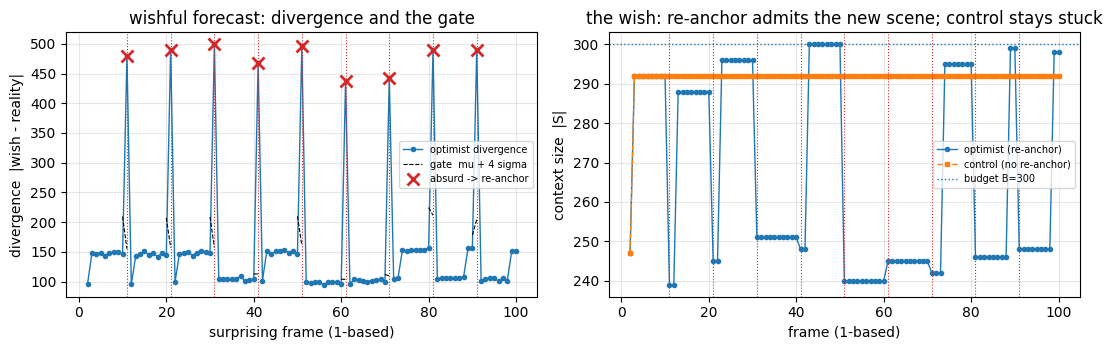

In [5]:
tt = list(range(2, len(clip_sets) + 1))     # 1-based surprising-frame ids
div_opt = np.array(opt["divs"], dtype=float)
thr = np.array([x if x is not None else np.nan for x in opt["thresholds"]],
               dtype=float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(tt, div_opt, "o-", ms=3, lw=1, label="optimist divergence")
ax1.plot(tt, thr, "k--", lw=0.8, label="gate  mu + %.0f sigma" % K)
for c in TRUE_CUTS:
    ax1.axvline(c, color="tab:red", ls=":", lw=0.8)
ax1.plot(opt["fires"], [div_opt[f - 2] for f in opt["fires"]],
         "x", ms=9, mew=2, color="tab:red", label="absurd -> re-anchor")
ax1.set_xlabel("surprising frame (1-based)")
ax1.set_ylabel("divergence  |wish - reality|")
ax1.set_title("wishful forecast: divergence and the gate")
ax1.legend(fontsize=7)
ax1.grid(alpha=0.3)

ax2.plot(tt, opt["Ss"], "o-", ms=3, lw=1, label="optimist (re-anchor)")
ax2.plot(tt, ctrl["Ss"], "s--", ms=3, lw=1, label="control (no re-anchor)")
ax2.axhline(B, color="tab:blue", ls=":", lw=1, label="budget B=%d" % B)
for c in TRUE_CUTS:
    ax2.axvline(c, color="tab:red", ls=":", lw=0.8)
ax2.set_xlabel("frame (1-based)")
ax2.set_ylabel("context size  |S|")
ax2.set_title("the wish: re-anchor admits the new scene; control stays stuck")
ax2.legend(fontsize=7)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

The prototype supports `docs/EWM_BASIS_STRATA.md` §8:

- the constraint model acted strictly as a **choice function**: the basis
  (the lattice side) kept everything, only the wish `S` was chosen, and the
  budget was the priority;
- divergence `|wish Δ reality| = |D| + |N|` held exactly at every turn, with
  both the wishful surplus `D` and the missed reality `N` nonzero;
- the `μ + kσ` gate fired at the scene cuts and re-anchoring restored
  forecast quality, while the no-re-anchor control stayed stuck in the old
  scene — optimism is productive only when the absurdity test can reject it;
- inside a scene the wish stabilized (the fixed point of the loop).

What this is *not*: a learned predictor. The null model is the simple
trailing `μ + kσ`; the project's EWMA-surprise portfolio (notebooks 10–12)
is the natural upgrade, and the exact SAT/SMT oracle of §7 remains the
offline benchmark.


In [6]:
passed = sum(1 for _, ok in CHECKS if ok)
print("checks: %d/%d passed" % (passed, len(CHECKS)))
assert all(ok for _, ok in CHECKS), "a law failed"
print("gate: mu + %.0f sigma over trailing W=%d, budget B=%d" % (K, W, B))
print("fires: %s" % opt["fires"])
print("docs: EWM_BASIS_STRATA.md §8 — wishful loop confirmed; the EWMA-surprise "
      "null model and the SAT/SMT oracle are the next upgrades")


checks: 8/8 passed
gate: mu + 4 sigma over trailing W=8, budget B=300
fires: [11, 21, 31, 41, 51, 61, 71, 81, 91]
docs: EWM_BASIS_STRATA.md §8 — wishful loop confirmed; the EWMA-surprise null model and the SAT/SMT oracle are the next upgrades
